# Задание 4.15
## Две точки в прямоугольнике (метод Монте-Карло)

### Условие:
В прямоугольнике $|x|\le20$, $|y|\le8$ случайно выбираются две точки $(x_1,y_1)$, $(x_2,y_2)$. $A$ — расстояние между точками меньше 11; $B$ — $|x_1-x_2|<14$. Найдите приближённо методом Монте-Карло 1) $\mathbb P(A)$; 2) $\mathbb P(A|B)$ (100 000 пар точек).

### Метод Монте-Карло:
Генерируем $N=100\,000$ пар независимых равномерных точек и считаем $\mathbb P(A)\approx\dfrac{N(A)}{N}$, $\ \mathbb P(A|B)=\dfrac{\mathbb P(A\cap B)}{\mathbb P(B)}\approx\dfrac{N(A\cap B)}{N(B)}$. Погрешность порядка $\sqrt{p(1-p)/N}\approx0{,}0015$, поэтому ответ можно давать с двумя знаками после запятой.

### Аналитическая проверка:
Так как расстояние $<11$ влечёт $|x_1-x_2|<11<14$, то $A\subset B$, и $\mathbb P(A|B)=\dfrac{\mathbb P(A)}{\mathbb P(B)}$. Разности $u=x_1-x_2$ и $v=y_1-y_2$ независимы и имеют треугольные плотности $f_U(u)=\dfrac{40-|u|}{1600}$ ($|u|\le40$), $f_V(v)=\dfrac{16-|v|}{256}$ ($|v|\le16$). Поэтому
$$\mathbb P(B)=1-\Bigl(\frac{40-14}{40}\Bigr)^2=1-0{,}65^2=0{,}5775,\qquad \mathbb P(A)=\iint_{u^2+v^2<121}f_U(u)f_V(v)\,du\,dv$$
(двойной интеграл вычисляется численно ниже).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

In [2]:
N = 100_000
x1, x2 = rng.uniform(-20, 20, N), rng.uniform(-20, 20, N)
y1, y2 = rng.uniform(-8, 8, N), rng.uniform(-8, 8, N)
dist = np.hypot(x1 - x2, y1 - y2)
A = dist < 11                                                   # событие A: расстояние меньше 11
B = np.abs(x1 - x2) < 14                                        # событие B: |x1 − x2| < 14
P_A_mc = A.mean(); P_AB_mc = (A & B).sum()/B.sum()
print(f'N = {N}:  N(A) = {A.sum()}, N(B) = {B.sum()}, N(A∩B) = {(A & B).sum()}')
print(f'1) P(A)   ≈ {P_A_mc:.4f}   →  {P_A_mc:.2f}  (до одного знака: {P_A_mc:.1f})')
print(f'2) P(A|B) ≈ {P_AB_mc:.4f}   →  {P_AB_mc:.2f}  (до одного знака: {P_AB_mc:.1f})')

N = 100000:  N(A) = 36790, N(B) = 57656, N(A∩B) = 36790
1) P(A)   ≈ 0.3679   →  0.37  (до одного знака: 0.4)
2) P(A|B) ≈ 0.6381   →  0.64  (до одного знака: 0.6)


### Точные значения (численное интегрирование) и независимая проверка большой выборкой

In [3]:
from scipy.integrate import dblquad

fU = lambda u: (40 - abs(u))/1600                                # плотность разности x1 − x2
fV = lambda v: (16 - abs(v))/256                                 # плотность разности y1 − y2
# область u² + v² < 121 симметрична, поэтому берём четверть (u, v ≥ 0) и умножаем на 4
P_A_exact = 4*dblquad(lambda v, u: fU(u)*fV(v), 0, 11, 0, lambda u: np.sqrt(121 - u*u))[0]
P_B_exact = 1 - (26/40)**2
print(f'точно: P(A) = {P_A_exact:.5f},  P(B) = {P_B_exact:.5f},  P(A|B) = P(A)/P(B) = {P_A_exact/P_B_exact:.5f}')
M = 5_000_000
a1, a2 = rng.uniform(-20, 20, (2, M)); b1, b2 = rng.uniform(-8, 8, (2, M))
AA = np.hypot(a1 - a2, b1 - b2) < 11; BB = np.abs(a1 - a2) < 14
print(f'большая выборка (5·10^6): P(A) = {AA.mean():.5f}, P(A|B) = {(AA & BB).sum()/BB.sum():.5f}')

точно: P(A) = 0.36920,  P(B) = 0.57750,  P(A|B) = P(A)/P(B) = 0.63931
большая выборка (5·10^6): P(A) = 0.36916, P(A|B) = 0.63937


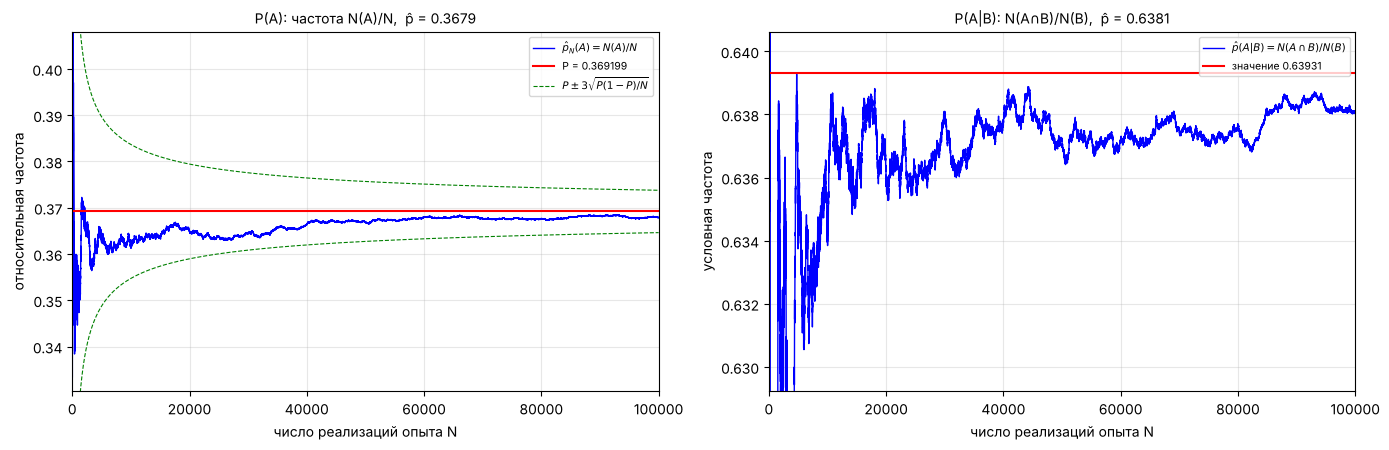

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
plot_frequency(axs[0], A, P_A_exact, f'P(A): частота N(A)/N,  p̂ = {P_A_mc:.4f}')
plot_conditional(axs[1], A & B, B, P_A_exact/P_B_exact, f'P(A|B): N(A∩B)/N(B),  p̂ = {P_AB_mc:.4f}')
plt.tight_layout(); plt.savefig('task_4_15.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
1) $\mathbb P(A)\approx0{,}37$; 2) $\mathbb P(A|B)\approx0{,}64$ (точные значения $0{,}3692$ и $0{,}6393$; с точностью до одного знака — $0{,}4$ и $0{,}6$).